### Import

In [1]:
import numpy as np
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt
import cv2
import os
from pathlib import Path
import albumentations as A

### Path

In [ ]:
#Insert path to dataset manually or use environment variable
# path = ""

metadata = pd.read_json( path + 'Fundus_CIMT_2903_Dataset/data_info.json')
retina_images = glob(path + 'Fundus_CIMT_2903_Dataset/images/*.png')

C:\Users\wessa\Desktop\Retinexes_code\


## Remove text overaly

### Testing removal

Testing overlay removal on top 5 images with white pixels...

432332001_L.png: Overlay removed
432332001_R.png: Overlay removed
429484001_R.png: Overlay removed
429484001_L.png: Overlay removed
152584002_R.png: Overlay removed


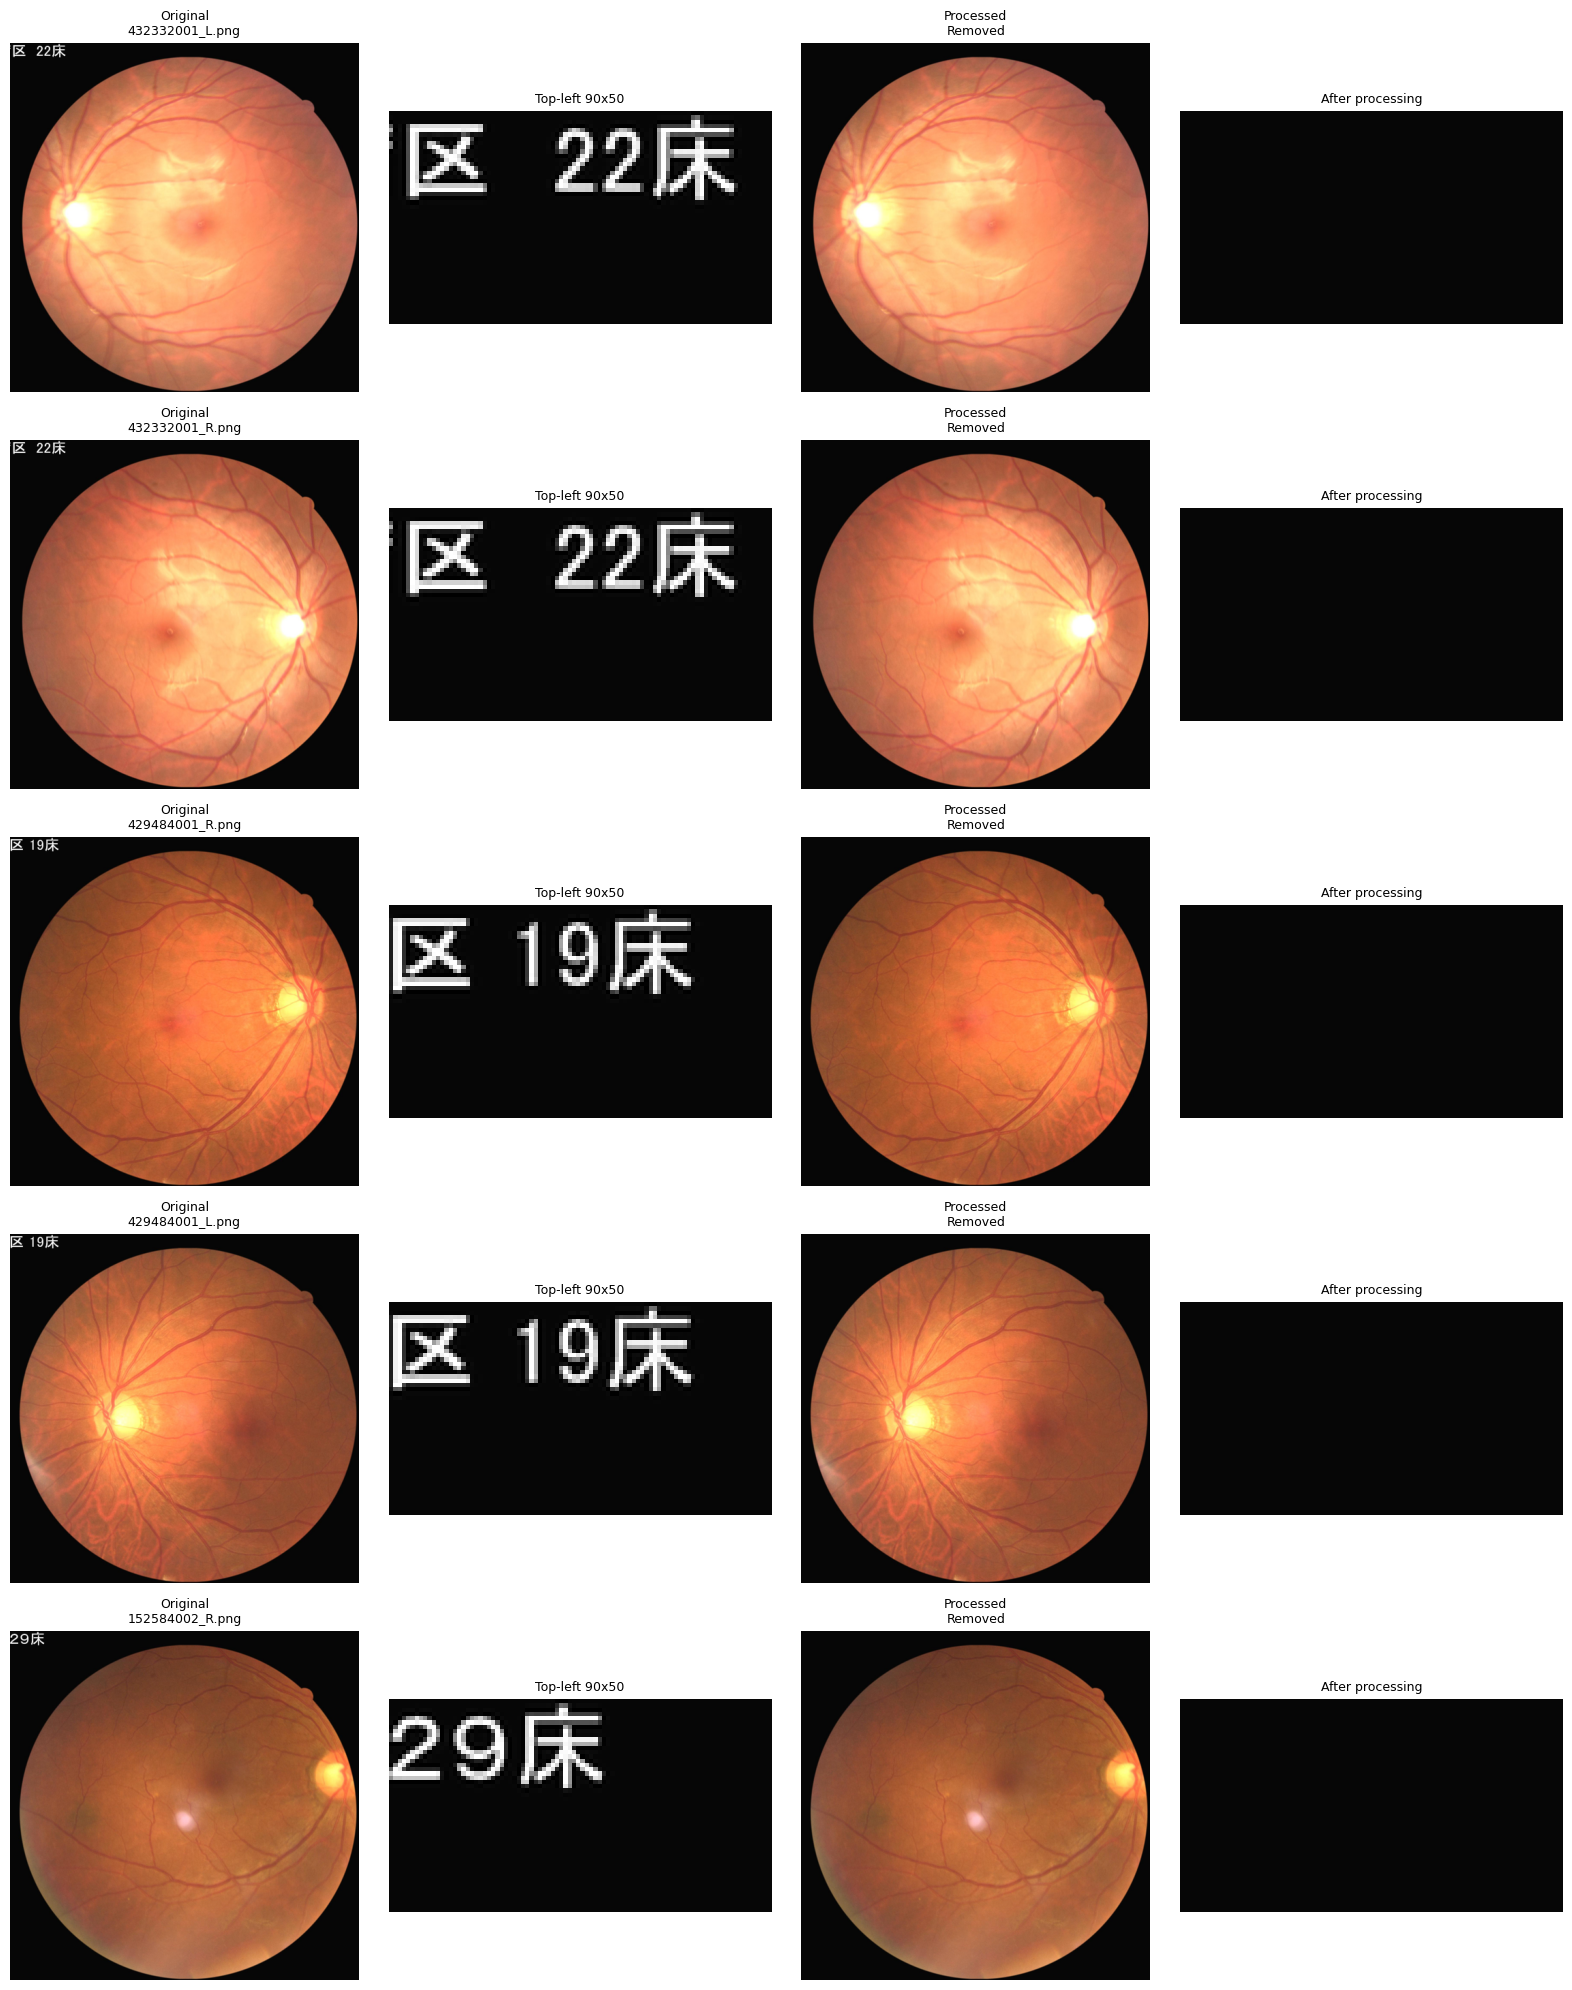

In [20]:
def remove_top_left_overlay(img, width=90, height=50, white_threshold=200, white_ratio=0.25):
    """
    Black out top-left corner if it has >25% white pixels.
    
    Args:
        img: Image array (RGB or BGR)
        width: Width of area to check (default 90)
        height: Height of area to check (default 50)
        white_threshold: Pixel value considered white (default 200)
        white_ratio: Ratio of white pixels to trigger blackout (default 0.25 = 25%)
    
    Returns:
        Modified image with top-left blacked out if needed
    """
    img_copy = img.copy()
    
    # Get top-left region
    top_left = img_copy[:height, :width]
    
    # Convert to grayscale to check intensity
    if len(top_left.shape) == 3:
        gray = cv2.cvtColor(top_left, cv2.COLOR_RGB2GRAY)
    else:
        gray = top_left
    
    # Count white pixels
    white_pixels = np.sum(gray > white_threshold)
    
    # Replace with fixed dark color if there's any white pixel
    if white_pixels > 0:
        fill_color = np.array([6, 6, 6], dtype=img_copy.dtype)
        img_copy[:height, :width] = fill_color
        return img_copy, True
    
    return img_copy, False


# Test on the top 5 images with white pixels in the top-left region
print("Testing overlay removal on top 5 images with white pixels...\n")

scores = []
for p in retina_images:
    img = cv2.imread(p)
    if img is None:
        continue
    top_left = img[:50, :90]
    gray = cv2.cvtColor(top_left, cv2.COLOR_BGR2GRAY)
    white_pixels = int(np.sum(gray > 200))
    if white_pixels > 0:
        scores.append((white_pixels, p))

scores.sort(reverse=True)
sample_paths = [p for _, p in scores[:5]]

if not sample_paths:
    print("No images with white pixels found in the top-left region.")
else:
    fig, axes = plt.subplots(len(sample_paths), 4, figsize=(16, 4 * len(sample_paths)))
    if len(sample_paths) == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, img_path in enumerate(sample_paths):
        img_bgr = cv2.imread(img_path)
        if img_bgr is None:
            continue
        img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        
        # Original
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"Original\n{Path(img_path).name}", fontsize=9)
        axes[i, 0].axis('off')
        
        # Top-left zoom
        axes[i, 1].imshow(img[:50, :90])
        axes[i, 1].set_title("Top-left 90x50", fontsize=9)
        axes[i, 1].axis('off')
        
        # Processed
        processed, had_overlay = remove_top_left_overlay(img)
        axes[i, 2].imshow(processed)
        axes[i, 2].set_title(f"Processed\n{'Removed' if had_overlay else 'No overlay'}", fontsize=9)
        axes[i, 2].axis('off')
        
        # Processed top-left zoom
        axes[i, 3].imshow(processed[:50, :90])
        axes[i, 3].set_title("After processing", fontsize=9)
        axes[i, 3].axis('off')
        
        print(f"{Path(img_path).name}: {'Overlay removed' if had_overlay else 'No overlay detected'}")

    plt.tight_layout()
    plt.show()

## Data Preprocessing Pipeline

In [2]:
# Install albumentations for RandAug if not already installed
try:
    import albumentations as A
except ImportError:
    import subprocess
    subprocess.check_call(['pip', 'install', 'albumentations'])
    import albumentations as A


class ImagePreprocessor:
    """
    Extensible image preprocessing pipeline.
    Add more techniques as methods and register them in techniques list.
    """
    
    def __init__(self):
        self.techniques = []
        
    def add_technique(self, name, func):
        """Add a preprocessing technique to the pipeline"""
        self.techniques.append((name, func))
        return self
    
    def process(self, img):
        """Apply all techniques in sequence"""
        for name, func in self.techniques:
            img = func(img)
        return img
    
    def process_batch(self, image_paths, output_dir, progress_interval=100):
        """Process all images and save to output directory"""
        os.makedirs(output_dir, exist_ok=True)
        
        print(f"Processing {len(image_paths)} images with {len(self.techniques)} technique(s)...\n")
        processed_count = 0
        
        for i, img_path in enumerate(image_paths):
            img = cv2.imread(img_path)
            if img is None:
                print(f"Failed to read: {img_path}")
                continue
            
            # Convert BGR to RGB for processing
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            
            # Apply pipeline
            processed = self.process(img_rgb)
            
            # Convert back to BGR for saving
            processed_bgr = cv2.cvtColor(processed, cv2.COLOR_RGB2BGR)
            
            # Save
            output_path = os.path.join(output_dir, Path(img_path).name)
            cv2.imwrite(output_path, processed_bgr)
            processed_count += 1
            
            if (i + 1) % progress_interval == 0:
                print(f"Processed {i + 1}/{len(image_paths)} images...")
        
        print(f"\nDone!")
        print(f"Total processed: {processed_count}/{len(image_paths)}")
        print(f"Saved to: {output_dir}")


# Define preprocessing techniques
def technique_remove_overlay(img):
    """Remove text overlay from top-left corner"""
    return remove_top_left_overlay(img)[0]


def technique_randaug(img):
    """Apply RandAug augmentation"""
    transform = A.Compose([
        A.RandAugment(num_layers=2, magnitude=6, p=0.5),
    ], bbox_params=None)
    
    augmented = transform(image=img)
    return augmented['image'].astype(np.uint8)


# Create pipeline and add techniques
preprocessor = ImagePreprocessor()
preprocessor.add_technique("remove_overlay", technique_remove_overlay)
preprocessor.add_technique("randaug", technique_randaug)

print("Pipeline created with techniques:")
for name, _ in preprocessor.techniques:
    print(f"  - {name}")

Pipeline created with techniques:
  - remove_overlay
  - randaug


In [ ]:
# Run the preprocessing pipeline on all images
output_dir = path + "Fundus_CIMT_2903_Dataset/images_preprocessed/"

preprocessor.process_batch(retina_images, output_dir, progress_interval=100)